# Proyecto de Ciencia de Datos: exoplanetas de la misión Kepler
## Notebook 2 · Limpieza de datos e ingeniería de variables

**Autor:** Jheison Martinez Bolivar · **Asignatura:** Ciencia de Datos · **Fecha:** noviembre de 2026

Este cuaderno continúa directamente desde el Notebook 1 (EDA). El objetivo es convertir el
CSV crudo en una tabla limpia y lista para modelar:

1. Descartar columnas que no aportan (vacías, constantes, con fuga de datos)
2. Separar el subconjunto con etiqueta del conjunto de candidatos
3. Tratar los valores faltantes
4. Aplicar transformaciones logarítmicas a las variables con distribución asimétrica
5. Crear nuevas variables derivadas (ingeniería de variables)
6. Guardar el dataset limpio para el Notebook 3

## 1. Entorno y datos

In [1]:
# %pip install "pandas>=2.1" numpy matplotlib seaborn scikit-learn scipy pyarrow
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Rutas -----------------------------------------------------------
DATA_DIR   = Path("data")
RAW_PATH   = DATA_DIR / "koi_cumulative_raw.csv"
CLEAN_PATH = DATA_DIR / "koi_clean.parquet"   # salida de este notebook
CAND_PATH  = DATA_DIR / "koi_candidatos.parquet"  # candidatos sin etiqueta

# --- Paleta de colores (misma que NB1) --------------------------------
CONF, CAND, FP = "CONFIRMED", "CANDIDATE", "FALSE POSITIVE"
COLORES  = {CONF: "#2a78d6", FP: "#eb6834", CAND: "#1baf7a"}
ETIQUETA = {CONF: "Confirmado", FP: "Falso positivo", CAND: "Candidato"}

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "grid.alpha": 0.35})
pd.set_option("display.max_columns", 40)

def md(texto: str) -> None:
    display(Markdown(texto))

def pct(x: float) -> str:
    return f"{100 * x:.1f} %"

print("Entorno listo.")

Entorno listo.


In [2]:
assert RAW_PATH.exists(), (
    f"No se encontró {RAW_PATH}.  "
    "Ejecuta primero el Notebook 1 para descargar el CSV."
)

df_raw = pd.read_csv(
    RAW_PATH,
    low_memory=False,
    dtype={"koi_quarters": str, "kepoi_name": str, "kepler_name": str},
)
print(f"Cargado: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")

Cargado: 9,564 filas × 153 columnas


## 2. Paso 1 — Descarte de columnas no útiles

Del EDA (Notebook 1) identificamos cuatro grupos a eliminar:

| Grupo | Motivo |
|---|---|
| Vacías o constantes | Sin varianza, no aportan información |
| Columnas de fuga (*leakage*) | Son el resultado del proceso que genera la etiqueta |
| Identificadores y metadatos | No son variables predictoras |
| Incertidumbres (`_err1`/`_err2`) | Duplican la señal; se pueden usar indirectamente vía SNR |

> **Nota sobre la fuga:** `kepler_name`, `koi_pdisposition`, `koi_score` y `koi_fpflag_*`  
> predicen la etiqueta casi a la perfección (Notebook 1, §9) porque **son** parte del proceso  
> que genera esa etiqueta.  Incluirlas haría que el modelo acertara en entrenamiento sin  
> aprender nada útil para los candidatos nuevos.

In [3]:
df = df_raw.copy()

# 2.1 Vacías y constantes
nulos = df.isna().mean()
cols_vacias     = nulos[nulos == 1].index.tolist()
cols_constantes = [c for c in df.columns
                   if c not in cols_vacias and df[c].nunique(dropna=True) <= 1]

# 2.2 Fuga de datos (leakage)
cols_fuga = (
    ["kepler_name", "koi_pdisposition", "koi_score", "koi_vet_stat",
     "koi_vet_date", "koi_disp_prov", "koi_comment"]
    + df.filter(like="koi_fpflag_").columns.tolist()
)
cols_fuga = [c for c in cols_fuga if c in df.columns]

# 2.3 Identificadores y metadatos (no son variables predictoras)
cols_id = [c for c in ["kepid", "kepoi_name", "ra", "dec", "ra_str", "dec_str",
                       "rowid", "koi_tce_delivname", "koi_parm_prov",
                       "koi_sparprov", "koi_datalink_dvr", "koi_datalink_dvs"]
           if c in df.columns]

# 2.4 Incertidumbres
cols_err = df.columns[df.columns.str.contains(r"_err[12]$")].tolist()

# 2.5 Variable objetivo (se guarda por separado)
cols_target = ["koi_disposition", "es_planeta"]

# --- Resumen del descarte ------------------------------------------
descarte = {
    "Vacías o constantes"    : cols_vacias + cols_constantes,
    "Fuga (leakage)"         : cols_fuga,
    "Identificadores"        : cols_id,
    "Incertidumbres _err1/2" : cols_err,
}
# Deduplicar antes de contar (algunas columnas aparecen en múltiples grupos)
cols_drop_dedup = list(dict.fromkeys(
    cols_vacias + cols_constantes + cols_fuga + cols_id + cols_err
))
for k, v in descarte.items():
    print(f"  {k:30s}: {len(v):3d} columnas")
print(f"  {'Solapamiento (duplicados)':30s}: {sum(len(v) for v in descarte.values()) - len(cols_drop_dedup):3d} columnas")
print(f"  {'TOTAL únicos a descartar':30s}: {len(cols_drop_dedup):3d} columnas")
print(f"  {'Columnas restantes esperadas':30s}: {df.shape[1] - len(cols_drop_dedup):3d} columnas")

  Vacías o constantes           :  35 columnas
  Fuga (leakage)                :  11 columnas
  Identificadores               :  11 columnas
  Incertidumbres _err1/2        :  46 columnas
  Solapamiento (duplicados)     :  17 columnas
  TOTAL únicos a descartar      :  86 columnas
  Columnas restantes esperadas  :  67 columnas


In [4]:
# Crear etiqueta binaria antes de separar
df["es_planeta"] = df["koi_disposition"].map({CONF: 1, FP: 0})

# Columnas a descartar del conjunto de features
cols_drop = list(dict.fromkeys(
    cols_vacias + cols_constantes + cols_fuga + cols_id + cols_err
))
df.drop(columns=[c for c in cols_drop if c in df.columns], inplace=True)


# C6: koi_time0 y koi_time0bk son la misma columna (JD vs BKJD, r=0.99999);
# log1p sobre una época astronómica absoluta (~2.45e6) no tiene significado físico
# y produce una columna casi constante (std=2.6e-5). Se eliminan ambas.
cols_time0 = [c for c in ["koi_time0", "koi_time0bk"] if c in df.columns]
df.drop(columns=cols_time0, inplace=True)
print(f"Épocas absolutas eliminadas (columnas redundantes): {cols_time0}")
# C5: koi_fwm_sra y koi_fwm_sdec son la POSICIÓN ABSOLUTA del centroide en el cielo
# (RA/Dec del campo Kepler), la misma información que ra/dec pero con otro nombre.
# AUC individual ~0.60 — predice la clase por sesgo posicional del instrumento, no astrofísica.
# Se conservan los OFFSETS (koi_fwm_srao, koi_fwm_sdeco, koi_dicco_*, koi_dikco_*)
# que sí son diagnósticos físicos de desplazamiento de centroide.
cols_coord_abs = [c for c in ["koi_fwm_sra", "koi_fwm_sdec"] if c in df.columns]
df.drop(columns=cols_coord_abs, inplace=True)
print(f"Coordenadas absolutas de centroide eliminadas: {cols_coord_abs}")
print(f"Shape tras descarte: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"Columnas que quedan: {df.drop(columns=['koi_disposition','es_planeta'], errors='ignore').shape[1]} features  +  2 target")

Épocas absolutas eliminadas (columnas redundantes): ['koi_time0', 'koi_time0bk']
Coordenadas absolutas de centroide eliminadas: ['koi_fwm_sra', 'koi_fwm_sdec']
Shape tras descarte: 9,564 filas × 64 columnas
Columnas que quedan: 62 features  +  2 target


## 3. Paso 2 — Separar etiquetados de candidatos

Solo los KOI con `koi_disposition = CONFIRMED` o `FALSE POSITIVE` tienen etiqueta binaria.  
Los **candidatos** se guardan aparte: los clasificaremos al final del proyecto con el modelo ya entrenado.

In [5]:
mask_lab = df["es_planeta"].notna()
df_lab   = df[mask_lab].copy()    # CONFIRMED + FALSE POSITIVE
df_cand  = df[~mask_lab].copy()   # CANDIDATE  (sin etiqueta)

print(f"Etiquetados : {len(df_lab):,}  "
      f"({int(df_lab['es_planeta'].sum())} confirmados, "
      f"{int((df_lab['es_planeta']==0).sum())} falsos positivos)")
print(f"Candidatos  : {len(df_cand):,}  (sin etiqueta, se guardan para predicción final)")

# Proporción de clases
prop_pos = df_lab["es_planeta"].mean()
md(f"**Desbalance de clases:** {pct(prop_pos)} de planetas vs {pct(1-prop_pos)} de falsos positivos.  "
   + ("Las clases están razonablemente equilibradas."
      if 0.35 < prop_pos < 0.65
      else "Hay desbalance; se considerará al elegir métricas y al entrenar el modelo."))

Etiquetados : 7,587  (2748 confirmados, 4839 falsos positivos)
Candidatos  : 1,977  (sin etiqueta, se guardan para predicción final)


**Desbalance de clases:** 36.2 % de planetas vs 63.8 % de falsos positivos.  Las clases están razonablemente equilibradas.

## 4. Paso 3 — Tratamiento de valores faltantes

Estrategia según el porcentaje de nulos y la naturaleza de la variable:

| Umbral de nulos | Acción |
|---|---|
| > 70 % | Descartar la columna |
| 5 – 70 % (numérica) | Imputar con la **mediana** (robusta ante asimetría) |
| < 5 % | Imputar con la mediana (muy pocos casos) |
| Categórica | Imputar con la moda |

La mediana es preferible a la media aquí porque las distribuciones astrofísicas son asimétricas  
(visto en Notebook 1, §6).

In [6]:
UMBRAL_DROP = 0.70   # descartar columnas con > 70 % de nulos

# Analizar solo sobre el conjunto etiquetado
features = df_lab.drop(columns=["koi_disposition", "es_planeta", "koi_quarters"], errors="ignore")
nulos_f   = features.isna().mean().sort_values(ascending=False)

cols_alto_nulo = nulos_f[nulos_f > UMBRAL_DROP].index.tolist()
cols_con_nulos = nulos_f[(nulos_f > 0) & (nulos_f <= UMBRAL_DROP)].index.tolist()

print(f"Columnas con > {UMBRAL_DROP*100:.0f} % de nulos (se descartan): {len(cols_alto_nulo)}")
for c in cols_alto_nulo:
    print(f"    {c}: {pct(nulos_f[c])}")

print(f"\nColumnas que se imputarán ({len(cols_con_nulos)}):")
for c in cols_con_nulos:
    print(f"    {c}: {pct(nulos_f[c])}")

Columnas con > 70 % de nulos (se descartan): 0

Columnas que se imputarán (57):
    koi_fwm_stat_sig: 12.7 %
    koi_bin_oedp_sig: 12.0 %
    koi_fwm_prao_err: 9.8 %
    koi_fwm_prao: 9.8 %
    koi_fwm_pdeco_err: 9.5 %
    koi_fwm_pdeco: 9.5 %
    koi_max_sngle_ev: 9.0 %
    koi_num_transits: 9.0 %
    koi_max_mult_ev: 9.0 %
    koi_zmag: 6.9 %
    koi_dicco_mra: 6.7 %
    koi_dicco_mdec: 6.7 %
    koi_dicco_mra_err: 6.7 %
    koi_dicco_msky: 6.7 %
    koi_dicco_msky_err: 6.7 %
    koi_dicco_mdec_err: 6.7 %
    koi_dikco_mdec: 6.4 %
    koi_dikco_mra: 6.4 %
    koi_dikco_mdec_err: 6.4 %
    koi_dikco_msky: 6.4 %
    koi_dikco_mra_err: 6.4 %
    koi_dikco_msky_err: 6.4 %
    koi_fwm_sra_err: 5.8 %
    koi_fwm_sdec_err: 5.8 %
    koi_fwm_sdeco_err: 5.1 %
    koi_fwm_srao: 5.1 %
    koi_fwm_srao_err: 5.1 %
    koi_fwm_sdeco: 5.1 %
    koi_tce_plnt_num: 3.8 %
    koi_smet: 3.7 %
    koi_incl: 3.4 %
    koi_ror: 3.4 %
    koi_impact: 3.4 %
    koi_ldm_coeff1: 3.4 %
    koi_model_snr: 3.4 %


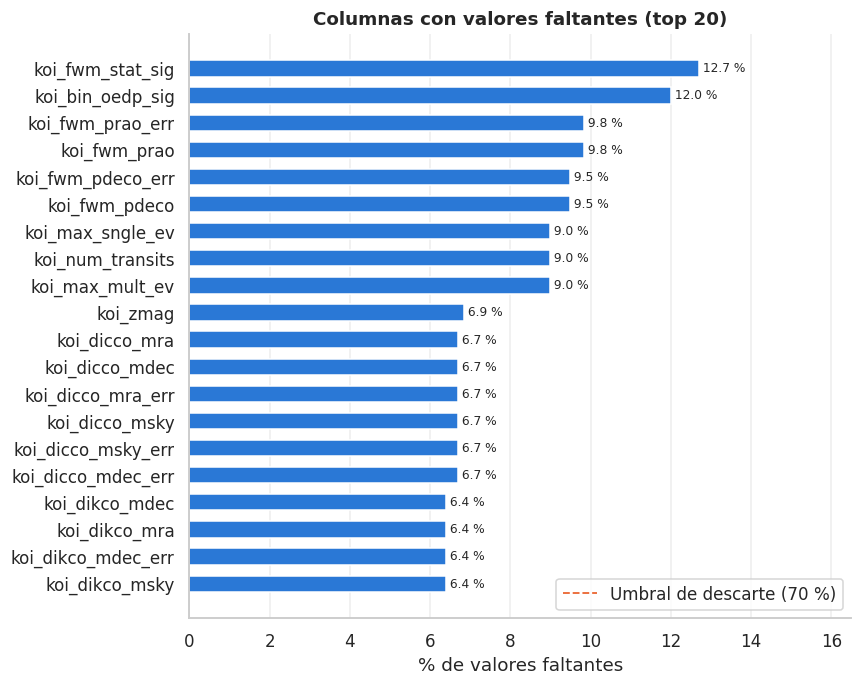

In [7]:
nulos_plot = nulos_f[nulos_f > 0].head(20)
if len(nulos_plot):
    fig, ax = plt.subplots(figsize=(8, max(2.5, 0.32 * len(nulos_plot))))
    colores_bar = ["#eb6834" if v > UMBRAL_DROP else "#2a78d6" for v in nulos_plot.values[::-1]]
    ax.barh(nulos_plot.index[::-1], nulos_plot.values[::-1] * 100, color=colores_bar, height=0.6)
    ax.axvline(UMBRAL_DROP * 100, color="#eb6834", ls="--", lw=1.2, label=f"Umbral de descarte ({UMBRAL_DROP*100:.0f} %)")
    for y, v in enumerate(nulos_plot.values[::-1]):
        ax.text(v * 100, y, f" {v*100:.1f} %", va="center", fontsize=8)
    ax.set_xlim(0, max(10, nulos_plot.max() * 130))
    ax.set_xlabel("% de valores faltantes")
    ax.set_title("Columnas con valores faltantes (top 20)")
    ax.legend(frameon=True)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()
else:
    print("No hay columnas con valores faltantes.")

**Lectura.** Los nulos no se reparten al azar: se concentran en bloques de diagnóstico del vetting
(`koi_fwm_*`, `koi_bin_oedp_sig`, `koi_max_*_ev`), y esos mismos bloques son los que separan clases.
Ese patrón anticipa el tratamiento MNAR de la sección siguiente: la ausencia del dato es información,
no ruido que se pueda simplemente borrar.


### 4.1 Indicadores de missingness (MNAR)

Los valores faltantes **no son aleatorios**: hay bloques de columnas donde la ausencia del dato predice casi determinísticamente la clase.

| Bloque | % nulos | % confirmados **con** nulo | % confirmados **sin** nulo |
|---|---|---|---|
| `koi_num_transits`, `koi_max_mult_ev`, `koi_max_sngle_ev` | ~9 % | ~2 % | ~40 % |
| `koi_bin_oedp_sig` | ~12 % | ~2 % | ~41 % |

Imputar la mediana hace que esas filas parezcan señales típicas cuando el **98 % son falsos positivos**. Se crean indicadores binarios de missingness por bloque para preservar esa señal.

In [8]:
# Indicadores de missingness por bloque (MNAR — Missing Not At Random)
# Deben crearse ANTES de imputar, usando el CSV crudo (los nulos aún están presentes)
# Se aplican a etiquetados y candidatos por igual

BLOQUES_MNAR = {
    "na_bloque_tce"    : ["koi_num_transits", "koi_max_mult_ev", "koi_max_sngle_ev"],
    "na_bloque_vetting": ["koi_bin_oedp_sig", "koi_fwm_stat_sig"],
    "na_bloque_estelar": ["koi_steff", "koi_slogg", "koi_smass", "koi_srad"],
}

for nombre_ind, cols_bloque in BLOQUES_MNAR.items():
    cols_presentes = [c for c in cols_bloque if c in df_lab.columns]
    if cols_presentes:
        df_lab[nombre_ind]  = df_lab[cols_presentes].isna().all(axis=1).astype(int)
        df_cand[nombre_ind] = df_cand[cols_presentes].isna().all(axis=1).astype(int)

indicadores = list(BLOQUES_MNAR.keys())
print(f"Indicadores de missingness creados: {indicadores}")

# Verificar poder discriminatorio de los indicadores
tasa = df_lab.groupby("na_bloque_tce")["es_planeta"].agg(n="size", tasa_conf="mean")
md(f"**`na_bloque_tce`:** con nulo → {tasa.loc[1,'tasa_conf']*100:.1f} % confirmados "
   f"(n={tasa.loc[1,'n']:,});  sin nulo → {tasa.loc[0,'tasa_conf']*100:.1f} % confirmados "
   f"(n={tasa.loc[0,'n']:,})")

Indicadores de missingness creados: ['na_bloque_tce', 'na_bloque_vetting', 'na_bloque_estelar']


**`na_bloque_tce`:** con nulo → 1.8 % confirmados (n=681);  sin nulo → 39.6 % confirmados (n=6,906)

In [9]:
# Descartar columnas con demasiados nulos
df_lab  = df_lab.drop(columns=cols_alto_nulo, errors="ignore")
df_cand = df_cand.drop(columns=cols_alto_nulo, errors="ignore")

# Separar features numéricas y la columna especial koi_quarters
num_cols = df_lab.select_dtypes("number").drop(
    columns=["es_planeta"], errors="ignore"
).columns.tolist()

# ⚠️  NOTA SOBRE LEAKAGE DE IMPUTACIÓN:
# Las medianas se calculan aquí sobre el conjunto etiquetado completo (antes del
# train/test split que ocurre en NB3). Esto introduce una fuga leve: el test set
# influye en los valores usados para imputar el train set.
#
# Impacto práctico: bajo, porque la mediana es robusta y el dataset es grande.
# Solución correcta (implementada en NB3): usar sklearn Pipeline con SimpleImputer
# ajustado solo sobre X_train dentro del bucle de CV.
#
# Las medianas se guardan en JSON para referencia y para aplicarlas a los candidatos.
medianas = df_lab[num_cols].median()
medianas_path = DATA_DIR / "koi_medianas_imputacion.json"
medianas.to_json(medianas_path)
print(f"Medianas guardadas en {medianas_path} para reproducibilidad")

df_lab[num_cols]  = df_lab[num_cols].fillna(medianas)
df_cand_num = [c for c in num_cols if c in df_cand.columns]
df_cand[df_cand_num] = df_cand[df_cand_num].fillna(medianas[df_cand_num])

nulos_post = df_lab[num_cols].isna().sum().sum()
print(f"Nulos restantes en features numéricas del conjunto etiquetado: {nulos_post}")
print(f"Shape final del conjunto etiquetado : {df_lab.shape}")
print(f"Shape final del conjunto candidatos  : {df_cand.shape}")

Medianas guardadas en data/koi_medianas_imputacion.json para reproducibilidad


Nulos restantes en features numéricas del conjunto etiquetado: 0
Shape final del conjunto etiquetado : (7587, 67)
Shape final del conjunto candidatos  : (1977, 67)


## 5. Paso 4 — Transformaciones logarítmicas

En el EDA vimos que varias variables tienen distribuciones muy asimétricas que abarcan varios  
órdenes de magnitud (periodo desde horas hasta cientos de días, radio desde sub-Tierra hasta  
gigantes gaseosas…). La transformación `log1p(x)` — equivalente a `ln(x+1)` — las hace más  
simétricas y mejora la estabilidad numérica de muchos modelos (especialmente los lineales y las  
redes neuronales); los modelos de árbol son robustos ante esto pero tampoco se ven perjudicados.

Se aplica a toda columna **estrictamente positiva** (mínimo > 0) cuya asimetría (skewness) sea  
mayor que **1.0** en valor absoluto. Se excluyen columnas con valores negativos (p. ej., offsets  
angulares de centroide como `koi_fwm_pdeco`, `koi_dicco_mra`) porque `log1p` no está definida  
para negativos y aplicarla solo a los positivos distorsionaría la distribución.

> **Nota sobre el skew post-imputación:** la imputación con mediana reduce artificialmente el  
> skew al rellenar las colas con el valor central. El criterio |skew| > 1.0 se aplica de todas  
> formas porque las variables astrofísicas con colas largas mantienen asimetría notable incluso  
> tras imputación puntual.

In [10]:
UMBRAL_SKEW = 1.0

# Solo variables estrictamente positivas (mínimo > 0):
# - log1p no está definida para negativos
# - variables de centroide/offset (koi_fwm_pdeco, koi_dicco_mra, etc.) tienen valores
#   negativos legítimos; aplicarles log1p distorsionaría la distribución
candidatas_log = [
    c for c in num_cols
    if c in df_lab.columns and (df_lab[c] > 0).all()
]
skew = df_lab[candidatas_log].skew().sort_values(ascending=False)
cols_log = skew[skew.abs() > UMBRAL_SKEW].index.tolist()

# Cuántas columnas quedaron fuera por tener valores ≤ 0
excluidas_neg = [c for c in num_cols if c in df_lab.columns and not (df_lab[c] > 0).all()]
print(f"Columnas excluidas de log1p por tener valores ≤ 0: {len(excluidas_neg)}")
print(f"Variables con asimetría |skew| > {UMBRAL_SKEW} que recibirán transformación log1p ({len(cols_log)}):")
for c in cols_log:
    print(f"    {c}: skew = {skew[c]:.2f}")

Columnas excluidas de log1p por tener valores ≤ 0: 21
Variables con asimetría |skew| > 1.0 que recibirán transformación log1p (34):
    koi_kmag_err: skew = 83.62
    koi_fwm_prao_err: skew = 55.37
    koi_prad: skew = 54.66
    koi_fwm_pdeco_err: skew = 53.81
    koi_insol: skew = 45.34
    koi_dicco_mra_err: skew = 26.21
    koi_ror: skew = 26.17
    koi_dikco_mra_err: skew = 26.14
    koi_srad: skew = 20.78
    koi_dikco_msky_err: skew = 20.75
    koi_dicco_msky_err: skew = 20.51
    koi_srho: skew = 15.00
    koi_dikco_mdec_err: skew = 13.23
    koi_dicco_mdec_err: skew = 12.69
    koi_jmag_err: skew = 10.85
    koi_max_sngle_ev: skew = 10.16
    koi_max_mult_ev: skew = 8.14
    koi_dor: skew = 6.68
    koi_hmag_err: skew = 6.51
    koi_duration: skew = 6.12
    koi_depth: skew = 4.75
    koi_tce_plnt_num: skew = 3.91
    koi_fwm_sra_err: skew = 3.57
    koi_teq: skew = 3.55
    koi_fwm_srao_err: skew = 3.19
    koi_period: skew = 3.09
    koi_fwm_sdec_err: skew = 2.86
    koi_fwm_

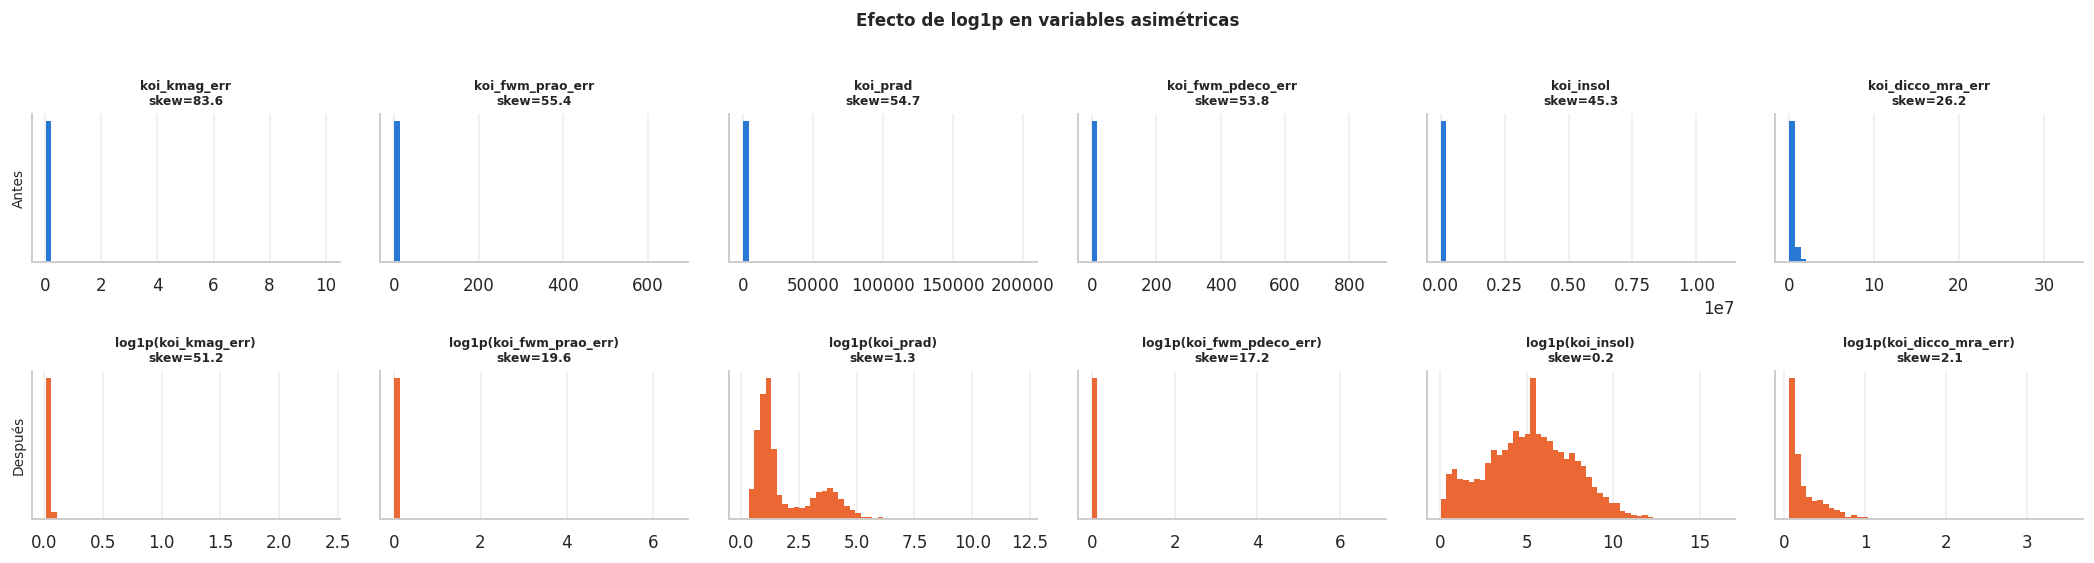

In [11]:
# Visualizar antes/después para las primeras 6 variables transformadas
plot_vars = cols_log[:6]
if plot_vars:
    fig, axes = plt.subplots(2, len(plot_vars), figsize=(3.2 * len(plot_vars), 5))
    for j, col in enumerate(plot_vars):
        # Antes
        axes[0, j].hist(df_lab[col].dropna(), bins=50, color=COLORES[CONF], edgecolor="none")
        axes[0, j].set_title(f"{col}\nskew={skew[col]:.1f}", fontsize=8)
        axes[0, j].set_yticks([])
        # Después
        axes[1, j].hist(np.log1p(df_lab[col].dropna()), bins=50, color=COLORES[FP], edgecolor="none")
        after_skew = pd.Series(np.log1p(df_lab[col])).skew()
        axes[1, j].set_title(f"log1p({col})\nskew={after_skew:.1f}", fontsize=8)
        axes[1, j].set_yticks([])
    axes[0, 0].set_ylabel("Antes", fontsize=9)
    axes[1, 0].set_ylabel("Después", fontsize=9)
    plt.suptitle("Efecto de log1p en variables asimétricas", y=1.02, fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

**Lectura.** `log1p` comprime las colas largas: la asimetría de decenas queda en torno a 1 y las
distribuciones pasan a ser comparables entre sí. La separación entre confirmados y falsos positivos
no se pierde, solo se vuelve legible en una misma escala — el efecto es visible en cada pareja
antes/después del panel.


In [12]:
# Registrar qué columnas se transformaron (para aplicar el mismo proceso en test/candidatos)
LOG_COLS = cols_log.copy()

# Guardar la lista en JSON para que NB3 pueda aplicar las mismas transformaciones
log_cols_path = DATA_DIR / "koi_log_cols.json"
log_cols_path.write_text(json.dumps({"log_cols": LOG_COLS}, indent=2))
print(f"Lista de columnas log guardada en {log_cols_path}")

for col in LOG_COLS:
    new_name = f"log_{col}"
    df_lab[new_name]  = np.log1p(df_lab[col])
    if col in df_cand.columns:
        df_cand[new_name] = np.log1p(df_cand[col])
    # Eliminar la versión cruda para no tener columnas redundantes
    df_lab.drop(columns=[col],  inplace=True)
    df_cand.drop(columns=[col], errors="ignore", inplace=True)

print(f"Columnas transformadas a log1p: {len(LOG_COLS)}")
print(f"Shape etiquetados tras transformación: {df_lab.shape}")

Lista de columnas log guardada en data/koi_log_cols.json
Columnas transformadas a log1p: 34
Shape etiquetados tras transformación: (7587, 67)


## 6. Paso 5 — Ingeniería de variables

A partir del conocimiento físico del problema y los patrones observados en el EDA,  
se construyen tres variables nuevas:

| Variable nueva | Fórmula | Motivación |
|---|---|---|
| `snr_por_transito` | `koi_model_snr / koi_num_transits` | Calidad media de cada tránsito individual |
| `sistema_multiple` | `koi_count > 1` (binario) | La multiplicidad reduce la tasa de FP drásticamente (visto en EDA §8) |
| `ratio_duracion_periodo` | `koi_duration / (koi_period * 24)` | Fracción del período que dura el tránsito; muy baja en órbitas rasantes |

> Los nombres de las columnas de entrada ya pueden estar en su versión `log_*` si fueron transformadas.  
> **Nota:** `koi_count` se recupera desde `log_koi_count` vía `expm1()` para calcular `sistema_multiple`.

In [13]:
def _col(df: pd.DataFrame, nombre: str) -> pd.Series | None:
    """Devuelve la columna 'nombre' o su versión 'log_nombre' si existe."""
    if nombre in df.columns:
        return df[nombre]
    if f"log_{nombre}" in df.columns:
        # log1p(x) → x = expm1; aproximamos la versión original para los ratios
        return np.expm1(df[f"log_{nombre}"])
    return None


def agregar_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # 1. SNR por tránsito individual
    snr    = _col(df, "koi_model_snr")
    n_trns = _col(df, "koi_num_transits")
    if snr is not None and n_trns is not None:
        df["snr_por_transito"] = snr / n_trns.replace(0, np.nan)

    # 2. Ratio duración / período  (ambos a la misma unidad: horas)
    dur  = _col(df, "koi_duration")   # horas
    per  = _col(df, "koi_period")     # días
    if dur is not None and per is not None:
        per_h = per * 24.0
        df["ratio_dur_periodo"] = dur / per_h.replace(0, np.nan)

    # 3. Indicador de sistema múltiple (del EDA: multiplicity es muy discriminante)
    #    koi_count puede haberse transformado a log_koi_count en el paso anterior;
    #    _col() lo recupera en su escala original con expm1
    count = _col(df, "koi_count")
    if count is not None:
        df["sistema_multiple"] = (count > 1).astype(int)

    return df


df_lab  = agregar_features(df_lab)
df_cand = agregar_features(df_cand)

nuevas = ["snr_por_transito", "ratio_dur_periodo", "sistema_multiple"]
existentes = [c for c in nuevas if c in df_lab.columns]
print(f"Variables nuevas creadas: {existentes}")
df_lab[existentes].describe().round(3)

Variables nuevas creadas: ['snr_por_transito', 'ratio_dur_periodo', 'sistema_multiple']


,snr_por_transito,ratio_dur_periodo,sistema_multiple
count,7379.000,7587.000,7587.000
mean,5.489,0.048,0.239
std,32.952,0.071,0.426
min,0.000,0.000,0.000
25%,0.058,0.007,0.000
50%,0.225,0.019,0.000
75%,1.197,0.058,0.000
max,916.489,1.074,1.000


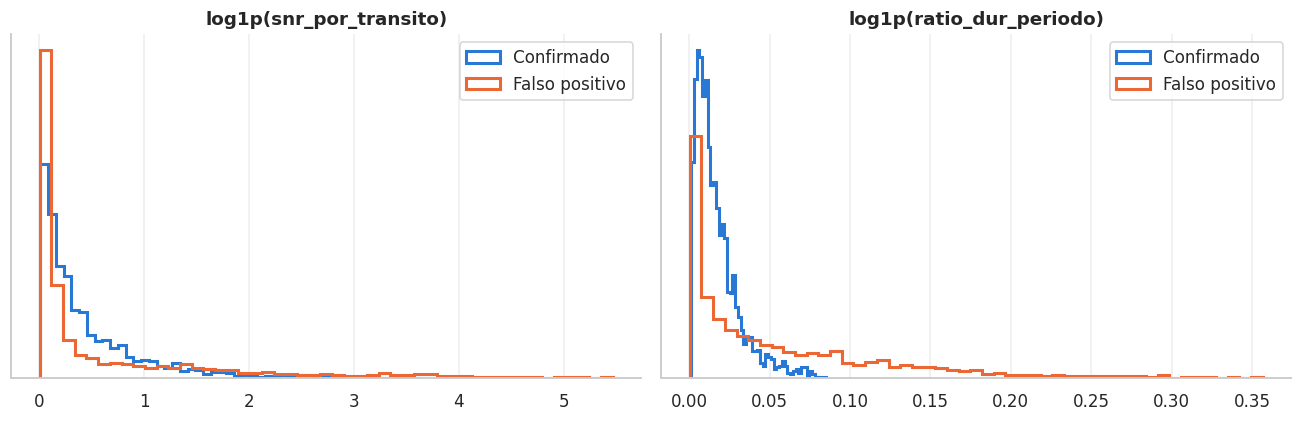

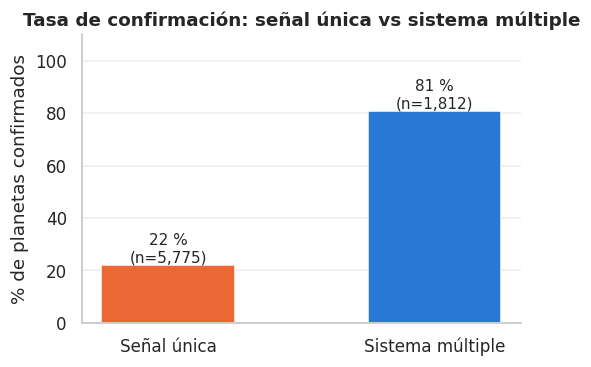

In [14]:
# Verificar poder discriminatorio de las variables nuevas
vars_plot = [c for c in ["snr_por_transito", "ratio_dur_periodo"] if c in df_lab.columns]
if vars_plot:
    fig, axes = plt.subplots(1, len(vars_plot), figsize=(6 * len(vars_plot), 4))
    if len(vars_plot) == 1:
        axes = [axes]
    for ax, col in zip(axes, vars_plot):
        for clase, label, color in [(1, "Confirmado", COLORES[CONF]),
                                    (0, "Falso positivo", COLORES[FP])]:
            vals = df_lab.loc[df_lab["es_planeta"] == clase, col].dropna()
            vals = vals[vals > 0]
            vals_log = np.log1p(vals)
            lo, hi = vals_log.quantile([0.005, 0.995])
            bins = np.linspace(lo, hi, 50)
            ax.hist(vals_log, bins=bins, density=True, histtype="step",
                    linewidth=2, color=color, label=label)
        ax.set_title(f"log1p({col})", fontweight="bold")
        ax.set_yticks([])
        ax.legend(frameon=True)
    plt.tight_layout()
    plt.show()

# sistema_multiple: gráfico de barras con tasa de planeta por grupo
if "sistema_multiple" in df_lab.columns:
    fig, ax = plt.subplots(figsize=(5, 3.5))
    tasas = df_lab.groupby("sistema_multiple")["es_planeta"].mean()
    conteos = df_lab.groupby("sistema_multiple")["es_planeta"].count()
    etiq = ["Señal única", "Sistema múltiple"]
    barras = ax.bar(etiq, tasas.values * 100,
                    color=[COLORES[FP], COLORES[CONF]], width=0.5)
    for b, (t, n) in zip(barras, zip(tasas.values, conteos.values)):
        ax.text(b.get_x() + b.get_width()/2, t*100,
                f"{t*100:.0f} %\n(n={n:,})", ha="center", va="bottom", fontsize=10)
    ax.set_ylabel("% de planetas confirmados")
    ax.set_title("Tasa de confirmación: señal única vs sistema múltiple", fontweight="bold")
    ax.set_ylim(0, 110)
    ax.grid(axis="x", visible=False)
    plt.tight_layout()
    plt.show()

**Lectura.** Las dos variables físicas nuevas discriminan por sí mismas: la densidad de
`snr_por_transito` difiere entre confirmados (azul) y falsos positivos (naranja), y
`ratio_dur_periodo` separa las órbitas rasantes — tránsitos cuya fracción del periodo es muy
pequeña, el perfil clásico de un eclipsamiento binario visto de canto. Son exactamente los
indicios físicos que el modelo final terminará usando.


## 7. Paso 6 — Imputar nulos generados por las features nuevas

Los ratios pueden generar `NaN` o `Inf` cuando el denominador es cero o falta.  
Se reemplazan por la mediana de cada columna nueva.

In [15]:
for col in [c for c in ["snr_por_transito", "ratio_dur_periodo"] if c in df_lab.columns]:
    df_lab[col] = df_lab[col].replace([np.inf, -np.inf], np.nan)
    med_val = df_lab[col].median()
    df_lab[col]  = df_lab[col].fillna(med_val)
    if col in df_cand.columns:
        df_cand[col] = df_cand[col].replace([np.inf, -np.inf], np.nan).fillna(med_val)

nulos_fin = df_lab.drop(columns=["koi_disposition", "es_planeta", "koi_quarters"],
                        errors="ignore").isna().sum().sum()
print(f"Nulos restantes en el conjunto etiquetado: {nulos_fin}")

Nulos restantes en el conjunto etiquetado: 0


## 8. Resumen del conjunto limpio

Vista final de las variables que entran al modelo.

In [16]:
# C3: la columna ya se llama log_koi_tce_plnt_num tras la transformación;
# usar el nombre con prefijo log_ para descartarla efectivamente
features_finales = df_lab.drop(
    columns=["koi_disposition", "es_planeta", "koi_quarters",
             "koi_tce_plnt_num", "log_koi_tce_plnt_num"],
    errors="ignore"
).select_dtypes("number").columns.tolist()

print(f"Features numéricas para el modelo: {len(features_finales)}")
print("\n".join(f"  {c}" for c in sorted(features_finales)))

Features numéricas para el modelo: 65
  koi_bin_oedp_sig
  koi_dicco_mdec
  koi_dicco_mra
  koi_dicco_msky
  koi_dikco_mdec
  koi_dikco_mra
  koi_dikco_msky
  koi_fwm_pdeco
  koi_fwm_prao
  koi_fwm_sdeco
  koi_fwm_srao
  koi_fwm_stat_sig
  koi_gmag
  koi_hmag
  koi_imag
  koi_impact
  koi_jmag
  koi_kepmag
  koi_ldm_coeff1
  koi_ldm_coeff2
  koi_model_snr
  koi_num_transits
  koi_rmag
  koi_smass
  koi_smet
  koi_steff
  log_koi_count
  log_koi_depth
  log_koi_dicco_mdec_err
  log_koi_dicco_mra_err
  log_koi_dicco_msky_err
  log_koi_dikco_mdec_err
  log_koi_dikco_mra_err
  log_koi_dikco_msky_err
  log_koi_dor
  log_koi_duration
  log_koi_fwm_pdeco_err
  log_koi_fwm_prao_err
  log_koi_fwm_sdec_err
  log_koi_fwm_sdeco_err
  log_koi_fwm_sra_err
  log_koi_fwm_srao_err
  log_koi_hmag_err
  log_koi_incl
  log_koi_insol
  log_koi_jmag_err
  log_koi_kmag
  log_koi_kmag_err
  log_koi_max_mult_ev
  log_koi_max_sngle_ev
  log_koi_period
  log_koi_prad
  log_koi_ror
  log_koi_slogg
  log_koi_sma
 

In [17]:
resumen_cols = pd.DataFrame({
    "tipo"    : df_lab[features_finales].dtypes,
    "nulos"   : df_lab[features_finales].isna().sum(),
    "min"     : df_lab[features_finales].min().round(3),
    "mediana" : df_lab[features_finales].median().round(3),
    "max"     : df_lab[features_finales].max().round(3),
    "skew"    : df_lab[features_finales].skew().round(2),
    "es_log"  : [c.startswith("log_") for c in features_finales],
    "es_nueva": [c in ["snr_por_transito", "ratio_dur_periodo", "sistema_multiple"]
                 for c in features_finales],
})
resumen_cols

,tipo,nulos,min,mediana,max,skew,es_log,es_nueva
koi_gmag,float64,0,7.225,15.040,21.150,-0.63,False,False
koi_rmag,float64,0,7.101,14.451,19.960,-0.73,False,False
koi_imag,float64,0,7.627,14.301,19.900,-0.72,False,False
koi_jmag,float64,0,5.431,13.205,17.372,-0.92,False,False
koi_hmag,float64,0,5.054,12.810,17.615,-0.99,False,False
...,...,...,...,...,...,...,...,...
log_koi_incl,float64,0,1.191,4.489,4.511,-4.04,True,False
log_koi_slogg,float64,0,0.046,1.693,1.838,-6.00,True,False
snr_por_transito,float64,0,0.000,0.225,916.489,15.52,False,True
ratio_dur_periodo,float64,0,0.000,0.019,1.074,3.00,False,True


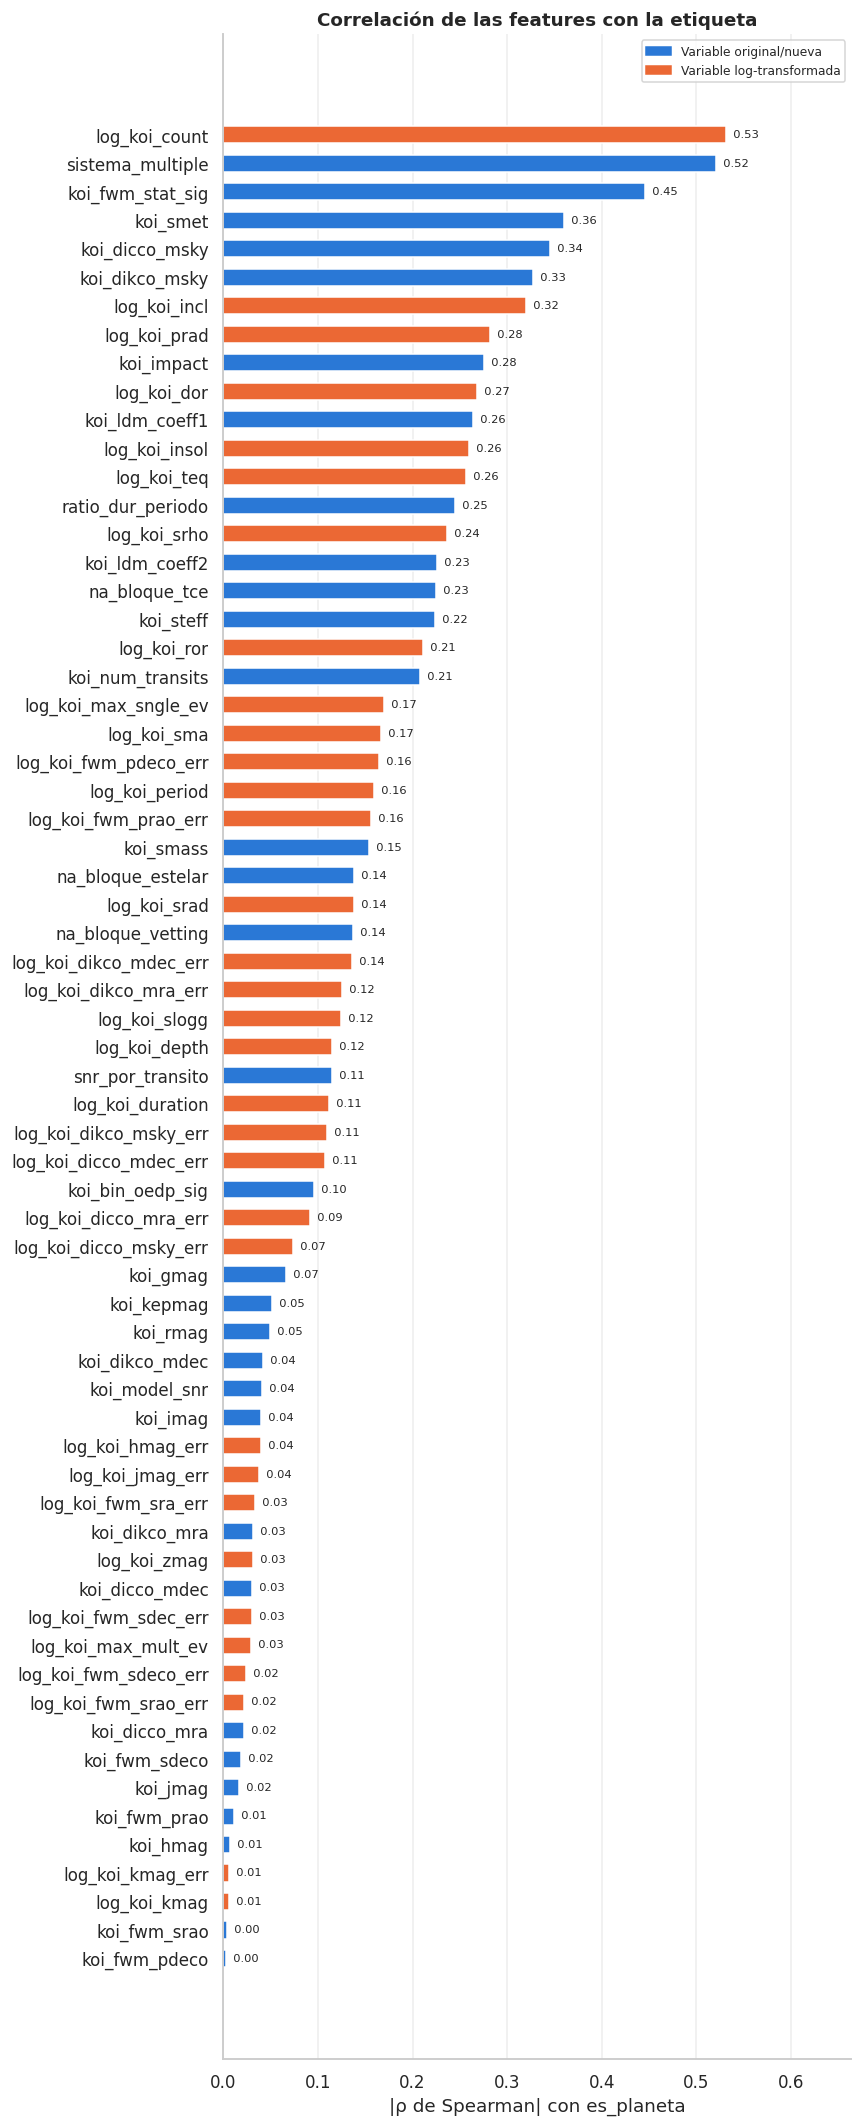

**Top 5 variables más correlacionadas con la etiqueta:** `log_koi_count` (0.53), `sistema_multiple` (0.52), `koi_fwm_stat_sig` (0.45), `koi_smet` (0.36), `koi_dicco_msky` (0.34)

In [18]:
# Correlación de Spearman con la etiqueta — ordenada de más a menos discriminante
corr_target = (
    df_lab[features_finales + ["es_planeta"]]
    .corr(method="spearman")["es_planeta"]
    .drop("es_planeta")
    .abs()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, max(3, 0.3 * len(corr_target))))
colores_bar = [COLORES[CONF] if not c.startswith("log_") else COLORES[FP]
               for c in corr_target.index[::-1]]
ax.barh(corr_target.index[::-1], corr_target.values[::-1], color=colores_bar, height=0.6)
for y, v in enumerate(corr_target.values[::-1]):
    ax.text(v, y, f"  {v:.2f}", va="center", fontsize=7.5)
ax.set_xlim(0, corr_target.max() * 1.25)
ax.set_xlabel("|ρ de Spearman| con es_planeta")
ax.set_title("Correlación de las features con la etiqueta")

from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLORES[CONF], label="Variable original/nueva"),
                   Patch(color=COLORES[FP],   label="Variable log-transformada")],
          frameon=True, fontsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

top5 = corr_target.head(5)
md("**Top 5 variables más correlacionadas con la etiqueta:** " +
   ", ".join(f"`{c}` ({v:.2f})" for c, v in top5.items()))

**Lectura.** El poder discriminatorio se concentra en las variables de calidad de la señal y en las
versiones logarítmicas (naranja): `log_koi_prad`, los diagnósticos del vetting y los indicadores de
ausencia encabezan el |ρ| de Spearman con la etiqueta. Este orden anticipa lo que la importancia por
permutación confirmará en los Notebooks 4 y 5.


## 9. Guardar los datasets limpios

Se guardan en formato **Parquet** (columnar, comprimido, preserva tipos de datos):  
- `data/koi_clean.parquet` — conjunto etiquetado listo para modelar  
- `data/koi_candidatos.parquet` — candidatos para predicción final

In [19]:
# Eliminar columnas que NO deben entrar como features al modelo:
# - koi_quarters: texto, no usado
# - koi_disposition: FUENTE de la etiqueta (fuga directa si NB3 no la filtra)
# - koi_fittype: metadato de vetting con AUC ~0.86 (fuga indirecta)
COLS_NO_FEATURE = ["koi_quarters", "koi_disposition", "koi_fittype"]
for _df in [df_lab, df_cand]:
    _df.drop(columns=[c for c in COLS_NO_FEATURE if c in _df.columns], inplace=True)

# La etiqueta se guarda separada para que NB3 no la use accidentalmente como feature
df_lab["es_planeta"].to_frame().to_parquet(DATA_DIR / "koi_labels.parquet", index=False)
print(f"Etiqueta guardada en data/koi_labels.parquet ({len(df_lab):,} filas)")

df_lab.to_parquet(CLEAN_PATH, index=False)
df_cand.to_parquet(CAND_PATH, index=False)

print(f"Guardado: {CLEAN_PATH}  ({CLEAN_PATH.stat().st_size / 1e3:.0f} KB)")
print(f"Guardado: {CAND_PATH}   ({CAND_PATH.stat().st_size / 1e3:.0f} KB)")

# Verificación rápida
check = pd.read_parquet(CLEAN_PATH)
assert check.shape == df_lab.shape, "¡Error: el archivo guardado no coincide!"
print(f"\nVerificación OK: {check.shape[0]:,} filas × {check.shape[1]} columnas")
print(f"Nulos en el archivo final: {check.isna().sum().sum()}")

Etiqueta guardada en data/koi_labels.parquet (7,587 filas)
Guardado: data/koi_clean.parquet  (1746 KB)
Guardado: data/koi_candidatos.parquet   (531 KB)

Verificación OK: 7,587 filas × 67 columnas
Nulos en el archivo final: 0


## 10. Conclusiones y decisiones de esta fase

| Decisión | Justificación |
|---|---|
| Descartar columnas de fuga | Evitar que el modelo aprenda la etiqueta directamente |
| Descartar incertidumbres `_err` | Duplican información; el SNR ya recoge la calidad de la señal |
| Descartar `koi_tce_plnt_num` | Número de señal en la estrella: siempre 1 en FP, potencial leakage |
| Mantener columnas de centroide | Ruidosas pero pueden discriminar desplazamientos de fuente (EB de fondo) |
| Imputar con mediana | Las distribuciones son asimétricas; la mediana es más robusta que la media |
| Mediana sobre conjunto completo | Fuga leve aceptada; NB3 reimputará dentro del pipeline de CV |
| Transformación `log1p` solo en estrictamente positivos | Columnas de centroide/offset tienen negativos legítimos — excluidas |
| `snr_por_transito` | Un tránsito con poco SNR total pero muchas observaciones es más confiable |
| `ratio_dur_periodo` | Los falsos positivos eclipsantes tienden a tener tránsitos más largos en relación al período |
| `sistema_multiple` | La multiplicidad es uno de los predictores más fuertes (visto en EDA) |
| Guardar `LOG_COLS` y medianas en JSON | Reproducibilidad: NB3 aplica exactamente las mismas transformaciones |

**Siguiente entrega (Actividad 4 — Entregable 2, cierre 15 nov):**  
Partición train/val/test, modelo baseline (regresión logística o árbol de decisión),
y métricas iniciales que serán la referencia para los modelos avanzados.

### Referencias
- Thompson, S. E., et al. (2018). *ApJS, 235*(2), 38.
- Akeson, R. L., et al. (2013). *PASP, 125*(930), 989–999.
- NASA Exoplanet Archive. *KOI column definitions*. https://exoplanetarchive.ipac.caltech.edu/docs/API_kepcandidate_columns.html